In [1]:
#pseudo code
#
#
#
#
#
#
#
#
#
#
# end :
#want somehtgn that solves the eoms and folllows the orbit of a rocket about the earth moon system
#need to solve for position of earth and moon along their orbits ==> use these to calculate the acceleration of the rocket 
# 
# we then test this work with the stabiity of the lagrnage L2 lunar point ,  should work for more than one lunar orbit 

In [30]:
import numpy as np
import math 
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
from scipy.integrate import solve_ivp


from scipy.optimize import brentq


In [25]:
#Constants
m_M= 7.35 *10**22
m_E=5.9742 *10**24
G = 6.6726 *10**-11
d = 3.844 * 10**8
earth_radius = 6.371e6 
moon_radius = 1.737e6


In [4]:
#calculated values /eqautions
r_m = d * (m_M/(m_M + m_E)) #distance from moon to barycentre
r_e = d * (m_E/(m_M + m_E)) #distance from earth to barycentre

def newton_grav(m1, m2, r):
    return G * m1 * m2 / r**2

def newton_grav_vector(m1,m2,r1,r2):
    return -G*m1*m2*(r2-r1)/np.linalg.norm(r2-r1)**3 

def force(m,a):
    return m*a  

def acceleration(F,m):
    return F/m





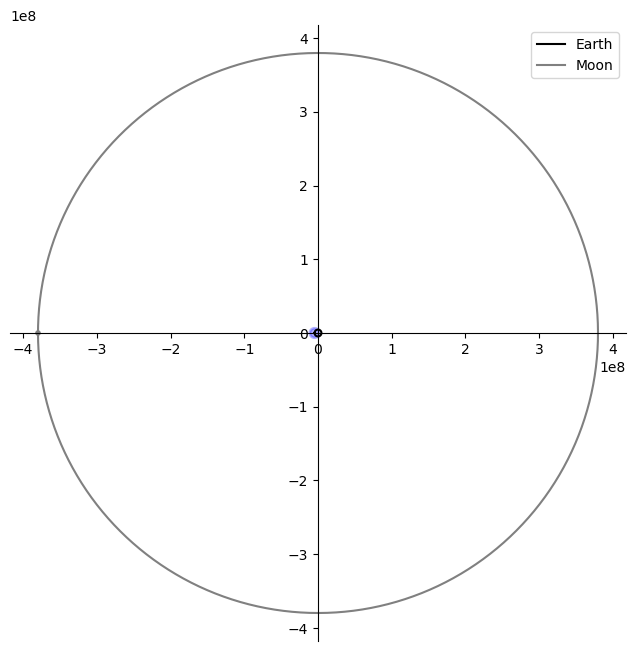

In [ ]:
def a_rocket(m1,m2,r,r1,r2):
    return -G*m1*(r-r1)/np.linalg.norm(r-r1)**3-G*m2*(r-r2)/np.linalg.norm(r-r2)**3

w = np.sqrt(G*(m_M+m_E)/d**3) 
def earth(t):
    return - m_M*d/(m_M+m_E)*np.array([np.cos(w*t),np.sin(w*t)])
def moon(t):
    return - m_E*d/(m_M+m_E)*np.array([np.cos(w*t),np.sin(w*t)])


times = np.linspace(0, 2*np.pi/w, 1000)

plt.figure()
plt.plot([earth(t)[0] for t in times], [earth(t)[1] for t in times], label='Earth', color='black')
plt.plot([moon(t)[0] for t in times], [moon(t)[1] for t in times], label='Moon', color='gray')
plt.legend()
plt.axis('equal')          # Same scale on x and y axes
plt.gca().set_aspect('equal', adjustable='box')
plt.gcf().set_size_inches(8, 8)  # Make the figure itself square
ax = plt.gca()

ax.spines['left'].set_position('zero')    # y-axis at x = 0
ax.spines['bottom'].set_position('zero')  # x-axis at y = 0

ax.spines['right'].set_color('none')
ax.spines['top'].set_color('none')

ax.xaxis.set_ticks_position('bottom')
ax.yaxis.set_ticks_position('left')

t = 0  # Choose the time you want to display
x_E, y_E = earth(t)

circleE = Circle((x_E, y_E), earth_radius,
                color='blue', fill=True, alpha=0.3,
                linewidth=2, label='Earth')

ax = plt.gca()
ax.add_patch(circleE)

x_M, y_M = moon(t)

circleM = Circle((x_M, y_M), moon_radius,
                color='gray', fill=True, alpha=0.8,
                linewidth=2, label='Moon')

ax = plt.gca()
ax.add_patch(circleM)

plt.gca().add_patch(circleM)
plt.show()


Text(0, 0.5, 'speed (km/s)')

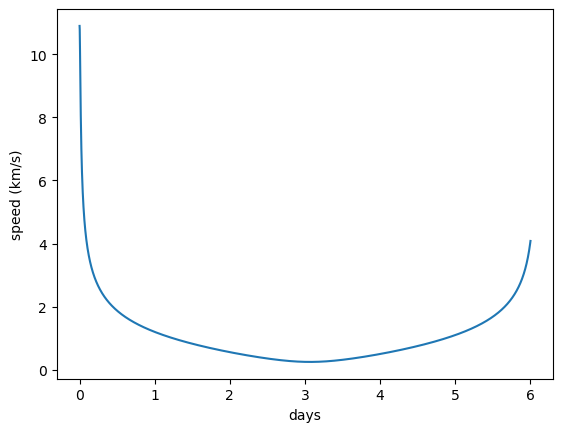

In [ ]:
def rhs(t, s):
    x, y, vx, vy = s
    r  = np.array([x, y])
    dE = r - earth(t)
    dM = r - moon(t)
    a = -G*m_E*dE/np.linalg.norm(dE)**3 - G*m_M*dM/np.linalg.norm(dM)**3
    return [vx, vy, a[0], a[1]]

# Start 200 km above Earth's surface, on the far side of Earth from the Moon, moving with v ~ 10.9 km/s
r0 = 6.371e6 + 2.0e5
e0 = earth(0)
s0 = [e0[0] - r0, e0[1], 0, -10.9e3]   # tangential velocity (plus Earth's own motion, ignored here for simplicity)

sol = solve_ivp(rhs, [0, 6*24*3600], s0, method="DOP853",
                rtol=1e-10, atol=1e-3, dense_output=True)

x, y = sol.y[0], sol.y[1]


t = np.linspace(0, sol.t[-1], 3000)
x, y, vx, vy = sol.sol(t)

moon_path = np.array([moon(ti) for ti in t])
speed = np.hypot(vx, vy)
plt.plot(t/86400, speed/1e3); plt.xlabel("days"); plt.ylabel("speed (km/s)")

In [36]:
dist_moon  = np.array([np.linalg.norm([x[i], y[i]] - moon(t[i])) for i in range(len(t))])
dist_earth = np.array([np.linalg.norm([x[i], y[i]] - earth(t[i])) for i in range(len(t))])

i = dist_moon.argmin()
print(f"Closest approach to Moon: {dist_moon[i]/1e3:.0f} km at day {t[i]/86400:.2f}")
print(f"Max distance from Earth: {dist_earth.max()/1e3:.0f} km")

Closest approach to Moon: 368485 km at day 0.00
Max distance from Earth: 275955 km


(np.float64(-30791309.51188055),
 np.float64(399276790.4881194),
 np.float64(-203539312.71448752),
 np.float64(9692348.224499406))

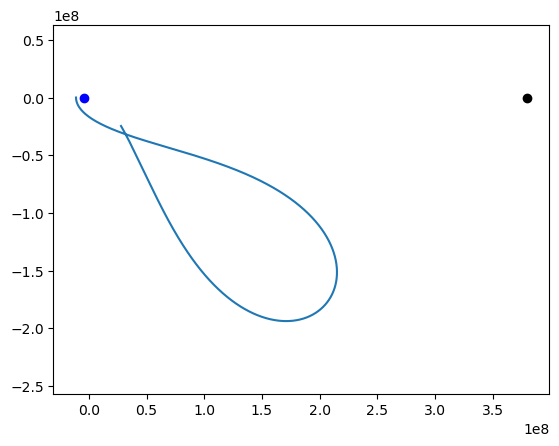

In [39]:
xr =  x*np.cos(w*t) + y*np.sin(w*t)
yr = -x*np.sin(w*t) + y*np.cos(w*t)
plt.plot(xr, yr)
plt.plot(-m_M/(m_E+m_M)*d, 0, "bo"); plt.plot(m_E/(m_E+m_M)*d, 0, "ko")
plt.axis("equal")